In [2]:
import gpflow
from gpflow.base import _cast_to_dtype
import tensorflow as tf
import numpy as np
from gpflow.utilities import ops, print_summary, to_default_float
from gpflow.config import set_default_float, default_float, set_default_summary_fmt
from gpflow.ci_utils import ci_niter
from gpflow.inducing_variables import InducingPoints
import matplotlib.pyplot as plt
from LVMOGP import LVMOGP
import pickle
import math
import tensorflow_probability as tfp
import pathlib as pl
import os
from test_functions import TestFun

os.environ['CUDA_VISIBLE_DEVICES'] = '-1'

2023-04-28 17:16:37.611231: I tensorflow/stream_executor/platform/default/dso_loader.cc:49] Successfully opened dynamic library libcudart.so.10.1


# Quick Notebook Showing how to fit the LVMOGP

In [3]:
seed=1
surface_type = 'linear_relation'
n_new_points=5
n_new_funs = 10
data_type_name = f'two_observed_{n_new_funs}_new'
n_fun = 2 + n_new_funs
total_train = 30*2 + 3 * n_new_points
n_points = [10]*2 + [n_new_points]*n_new_funs
n_train = n_points

set_opt_seed = False

same_points = False
plot_figs = True

train_inducing = True
domain = [0, 2]
latent_dims = 2
latent_dims_lvmogp = 2
observed_dims = 1
max_points = 60

noise = 0.05
n_grid_points = 100
continuous_dims = ['x1', 'x2'][:observed_dims]
lengthscales_x = [0.3, 0.3]
lengthscales_h = [0.4, 0.4, 0.4, 0.4, 0.4, 0.4][:latent_dims]


test_fun = TestFun(domain=domain, seed=seed, n_fun=n_fun,
                   observed_dims=observed_dims, test_type=surface_type, latent_dims=latent_dims, max_points=max_points,
                   noise=noise, n_grid_points=n_grid_points, same_points=same_points, lengthscales_X=lengthscales_x,
                   lengthscales_H=lengthscales_h)

2023-04-28 17:16:39.748490: I tensorflow/compiler/jit/xla_cpu_device.cc:41] Not creating XLA devices, tf_xla_enable_xla_devices not set
2023-04-28 17:16:39.749006: I tensorflow/stream_executor/platform/default/dso_loader.cc:49] Successfully opened dynamic library libcuda.so.1
2023-04-28 17:16:39.771629: E tensorflow/stream_executor/cuda/cuda_driver.cc:328] failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected
2023-04-28 17:16:39.771643: I tensorflow/stream_executor/cuda/cuda_diagnostics.cc:169] retrieving CUDA diagnostic information for host: ruby-System-Product-Name
2023-04-28 17:16:39.771646: I tensorflow/stream_executor/cuda/cuda_diagnostics.cc:176] hostname: ruby-System-Product-Name
2023-04-28 17:16:39.771694: I tensorflow/stream_executor/cuda/cuda_diagnostics.cc:200] libcuda reported version is: 515.43.4
2023-04-28 17:16:39.771707: I tensorflow/stream_executor/cuda/cuda_diagnostics.cc:204] kernel reported version is: 515.43.4
2023-04-28 17:16:39.771711: I

## Generate and Plot the Data

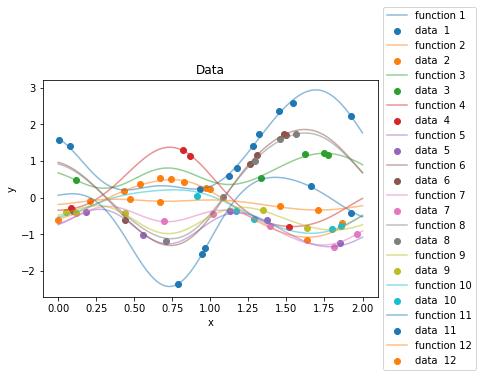

In [4]:
data_X, fun_nos, data_y = test_fun.create_data(n_points=n_points)


if plot_figs:
    test_fun.plot_data(n_points)

## Fit the LVMOGP

Randomly initialise the hyperparameters

In [5]:
H_mean = np.random.uniform(-1, 1, (n_fun, latent_dims_lvmogp))
H_mean = tf.convert_to_tensor(H_mean, dtype=default_float())
H_var = tf.ones((len(H_mean), latent_dims_lvmogp), dtype=default_float()) * 1e-6
kern_var = np.random.uniform(0, 1)
Ls_observed = np.random.uniform(0, 1, observed_dims)
Ls_latent = np.random.uniform(0, 1, latent_dims_lvmogp)
Ls = Ls_observed.tolist() + Ls_latent.tolist()
lengthscales = tf.convert_to_tensor(Ls, dtype=default_float(), name='lengthscales')
kern_variance = tf.convert_to_tensor(kern_var, dtype=default_float(), name='variance')
lik_variance = np.var(data_y)*0.01
kernel_lvmogp = gpflow.kernels.RBF(lengthscales=lengthscales, variance=kern_variance)
n_u = 200

Make the LVMOGP

In [6]:
lvmogp = LVMOGP(data=data_y,
                           X_data=data_X,
                           X_data_fn=fun_nos,
                           H_data_mean=H_mean,
                           H_data_var=H_var,
                           kernel=kernel_lvmogp,
                           num_inducing_variables=n_u,
                           inducing_variable=None,
                           H_prior_mean=None,
                           H_prior_var=None)
lvmogp.likelihood.variance.assign(to_default_float(lik_variance))

<tf.Variable 'UnreadVariable' shape=() dtype=float64, numpy=-4.523935953061312>

Train it

Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `export AUTOGRAPH_VERBOSITY=10`) and attach the full output.
Cause: module 'gast' has no attribute 'Index'
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert
Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `export AUTOGRAPH_VERBOSITY=10`) and attach the full output.
Cause: module 'gast' has no attribute 'Index'
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert


2023-04-28 17:16:40.398903: W tensorflow/python/util/util.cc:348] Sets are not currently considered sequences, but this may change in the future, so consider avoiding using them.
2023-04-28 17:16:40.943247: I tensorflow/compiler/mlir/mlir_graph_optimization_pass.cc:116] None of the MLIR optimization passes are enabled (registered 2)
2023-04-28 17:16:40.968333: I tensorflow/core/platform/profile_utils/cpu_utils.cc:112] CPU Frequency: 3600000000 Hz


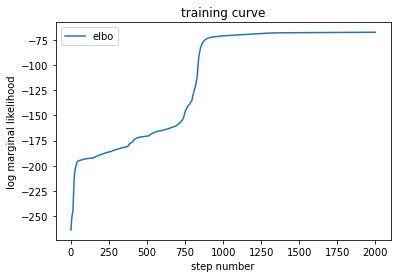

In [7]:
elbo = []

def step_callback(step, variables, values):
        elbo.append(lvmogp.elbo().numpy())

maxiter = 2000
lvm_opt = gpflow.optimizers.Scipy().minimize(
    lvmogp.training_loss, lvmogp.trainable_variables, options=dict(maxiter=maxiter), method="L-BFGS-B",
    step_callback=step_callback)

plt.plot(np.arange(len(elbo)), np.array(elbo), label=f'elbo')
# plt.hlines(indi_noise_lml, 0, len(lml), color='r', label='noise model')

plt.xlabel('step number')
plt.ylabel('log marginal likelihood')
plt.title(f'training curve')
plt.legend()

Predict on new points

In [14]:
x_new = np.linspace(domain[0], domain[1], 100).reshape(100, 1)

xs_new = np.vstack([x_new]*n_fun)
X_data_fun_new = np.hstack([[fun_no]*len(x_new) for fun_no in np.unique(fun_nos)])
fun_nos_new = X_data_fun_new
H_mean_vect = tf.reshape(tf.gather(_cast_to_dtype(lvmogp.H_data_mean, dtype=default_float()),
                                      _cast_to_dtype(X_data_fun_new, dtype=tf.int64)),
                                   [len(xs_new), latent_dims])
H_var_vect = tf.reshape(tf.gather(_cast_to_dtype(lvmogp.H_data_var, dtype=default_float()),
                                  _cast_to_dtype(X_data_fun_new, dtype=tf.int64)),
                                   [len(xs_new), latent_dims])

Xnew_mean = tf.concat([tf.convert_to_tensor(xs_new, default_float()), H_mean_vect], axis=1)
Xnew_var = tf.concat([tf.zeros(xs_new.shape, dtype=default_float()), H_var_vect], axis=1)
Xnew = [Xnew_mean, Xnew_var]
lvm_mu, lvm_sig2 = lvmogp.predict_y(Xnew)

Plot the predictions and the latent coordinates

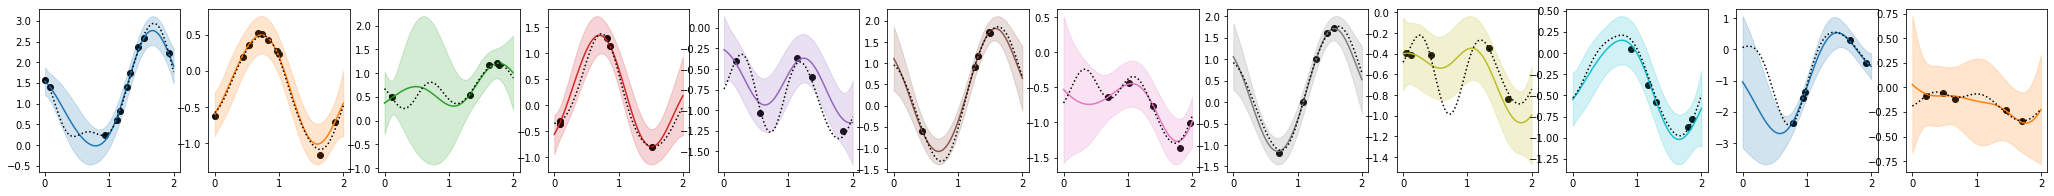

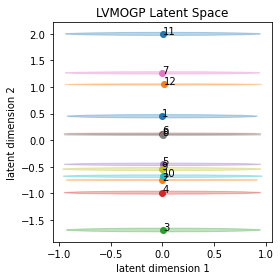

In [15]:
from matplotlib.patches import Ellipse
ys_new = []
for fun in test_fun.functions:
    y_new, _ = fun.predict_y(x_new)
    ys_new.append(y_new)


fig, axs = plt.subplots(1, ncols=n_fun, figsize=( 3 *n_fun, 3))
ax = axs.flatten()
colors = plt.rcParams['axes.prop_cycle'].by_key()['color'] * 100
for i, fun_no in enumerate(np.unique(fun_nos)):
    idx = np.where(fun_nos_new == fun_no)[0]
    ax[i].plot(x_new, lvm_mu.numpy()[idx], color=colors[i])
    ax[i].scatter(test_fun.xs[i][:n_points[i]], test_fun.ys[i][:n_points[i]], color='k')
    ax[i].plot(x_new, ys_new[i], linestyle=':', color='k')
    ax[i].fill_between(x_new.flatten(), lvm_mu.numpy()[idx].flatten() + 2 *np.sqrt(lvm_sig2.numpy()[idx].flatten()),
                       lvm_mu.numpy()[idx].flatten() - 2 * np.sqrt(lvm_sig2.numpy()[idx].flatten()),
                       alpha=0.2, color=colors[i])
    # ax[i].scatter(lvmogp.inducing_variable.Z.numpy()[:, 0],
    #               [-2.95] * len(lvmogp.inducing_variable.Z.numpy()), color='k', marker='x')

plt.show()


fig = plt.figure(figsize=(4, 4))
axsH = plt.gca()
colors = plt.rcParams['axes.prop_cycle'].by_key()['color'] * 100
for i, H_coord in enumerate(lvmogp.H_data_mean.numpy()):
    axsH.scatter(H_coord[0], H_coord[1], label=f'{i + 1}', color=colors[i])
    axsH.annotate(f'{i + 1}', (H_coord[0], H_coord[1]))
    axsH.set_title(f"LVMOGP Latent Space")
    axsH.set_xlabel(f'latent dimension 1')
    axsH.set_ylabel(f'latent dimension 2')
    circle1 = Ellipse((H_coord[0], H_coord[1]),
                      1.95 * np.sqrt(lvmogp.H_data_var.numpy()[i, 0]),
                      1.95 * np.sqrt(lvmogp.H_data_var.numpy()[i, 1])
                      , color=colors[i], alpha=0.3, zorder=0)
    # axsH.scatter(lvmogp.inducing_variable.Z[:, 1],lvmogp.inducing_variable.Z[:, 2], color='k', marker='x')
    axsH.add_patch(circle1)
plt.tight_layout()